# Assignment 2: PCA

This assignment has **50 marks (6.5% of final grades)**.


**Deadline: October 30 at 11:59PM**


We will cover a variety of lectures and tutorials in this assignment, including PCA and classification.

Please note that similar codes between individuals will considered violation under the academic integrity policy, and the instructor holds the right to take any necessarry action.

## Note
* Use Google Colab to do this assignment.
* Don't change existing code or text.
* Add code and write text as instructed.
* Please pay attention to questions asked after writing code to analyze or conclude results (I usually put them in bullet points and bold them)

## Submission
* File > Download > (as .ipynb)
* Submit .ipynb file on the Learn.
* Please submit by the deadline

## Submission Notes
(Please write any notes or assumptions here that you think we should know during marking)

# [NO MARKS] PCA Warming Up (Please go through it and have some fun :) )

Some code to illustrate examples of PCA using sklearn library vs original equations from Lecture 5.

**Let's create some random `5d` data**

In [1]:
import numpy as np
from sklearn.decomposition import PCA

# 100 points of 5d data
data = np.random.rand(100, 5)

**Lets convert this `5d` data to `2d` using `PCA`**


In [2]:
# n_components=2 because I want to convert 5d data to 2d i.e, d=5 and k=2 based on the notation in Tutorial.
pca = PCA(n_components=2)
pca.fit(data)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In code above when we call `fit`, it populates two things in `pca`:
1. `mean_`
2. `components_`

In [3]:
# mean of the input data (per dimension) used to zeroying the mean
pca.mean_

array([0.48383991, 0.49197538, 0.54262438, 0.51403607, 0.51635467])

In [4]:
# basis vectors: k by d projection marix (this is the transposed of projection matrix seen in Lecture 5)
pca.components_

array([[ 0.03955068,  0.22074302,  0.81712361,  0.32499914, -0.41999147],
       [ 0.48881227,  0.47488817,  0.16922086,  0.10291537,  0.70449735]])

Now we are ready to transform `5d` from `data` into `2d` using following code

In [5]:
data_to_reduce = data[:10]
reduced_data = np.dot(data_to_reduce - pca.mean_, pca.components_.T)

# reduced data from 5d to 2d
reduced_data.shape

(10, 2)

You can accomplish the same using `transform` function provided in `pca`

In [6]:
pca.transform(data_to_reduce).shape

(10, 2)

Time for inverse transform or changing `2d` data back to `5d`

Compression --> Decompression

In [7]:
decompressed_data = np.dot(reduced_data, pca.components_) + pca.mean_
decompressed_data

array([[0.52855227, 0.55343873, 0.63753312, 0.55475712, 0.53363892],
       [0.49292798, 0.4978046 , 0.53255044, 0.51073878, 0.53730152],
       [0.33011746, 0.4024594 , 0.753052  , 0.58558638, 0.13827875],
       [0.19292965, 0.23685031, 0.56309317, 0.5005497 , 0.02513921],
       [0.17188247, 0.14445351, 0.23874583, 0.37114898, 0.18304278],
       [0.46699802, 0.47794771, 0.54708128, 0.5145449 , 0.48597385],
       [0.31316477, 0.35835558, 0.62540726, 0.53401922, 0.18614361],
       [0.5134912 , 0.58107898, 0.81860206, 0.62500942, 0.40133696],
       [0.70287902, 0.71688537, 0.67182011, 0.58118753, 0.80035952],
       [0.6349196 , 0.71481897, 0.93013573, 0.67796722, 0.53508499]])

In [8]:
# same can we accomplished using inverse_transform
pca.inverse_transform(pca.transform(data_to_reduce))

array([[0.52855227, 0.55343873, 0.63753312, 0.55475712, 0.53363892],
       [0.49292798, 0.4978046 , 0.53255044, 0.51073878, 0.53730152],
       [0.33011746, 0.4024594 , 0.753052  , 0.58558638, 0.13827875],
       [0.19292965, 0.23685031, 0.56309317, 0.5005497 , 0.02513921],
       [0.17188247, 0.14445351, 0.23874583, 0.37114898, 0.18304278],
       [0.46699802, 0.47794771, 0.54708128, 0.5145449 , 0.48597385],
       [0.31316477, 0.35835558, 0.62540726, 0.53401922, 0.18614361],
       [0.5134912 , 0.58107898, 0.81860206, 0.62500942, 0.40133696],
       [0.70287902, 0.71688537, 0.67182011, 0.58118753, 0.80035952],
       [0.6349196 , 0.71481897, 0.93013573, 0.67796722, 0.53508499]])

In [9]:
# Lets find compression decompression error (absolute mean error)
100*np.sum(np.abs(data_to_reduce - decompressed_data))/data_to_reduce.size

np.float64(15.463523303063704)

# Dimensionality Reduction

## Problem 1: Visualize eigenvectors in face dataset: Eigenfaces [35 pts]

The following code load the face dataset which we used in the class demo as well:



In [10]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.images.shape)

(1348, 62, 47)


Clearly there are 1348 images each with the size of (62,47). The following code plot the first 7 images in this dataset:

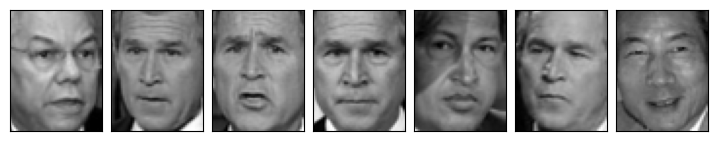

In [11]:
# Plot the images
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 7, figsize=(9, 5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(7):
    ax[i].imshow(faces.images[i], cmap='binary_r')

## 1a) [5 pts]
Use reshape method to reshape this data from (1348, 62, 47)
to (1348, 2914) such that X is the reshaped data:


In [13]:
#write your code here to reshape the data
# Assert the Input Shape
assert faces.images.shape == (1348, 62, 47)

# Reshape into X
X = faces.images.reshape(1348, -1)

# Assert the X.shape
assert X.shape == (1348, 2914)

## 1b) [5 pts]
Import PCA from sklearn and fit your model on X dataset using 150 principal components.

In [14]:
# write your commented code here
# Create PCA with 150 principle components
pca = PCA(n_components=150)
# Fit the data with the model
pca.fit(X)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",150
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SV

## 1c) [5 pts]
The components_ attribute return the projection matrix in $k$ by $d$ format i.e, each row is an eigenvector. Choose the first eigenvector of the covariance matrix (first row in of projection matrix extracted by components_ attribute), this should be a 1 by $d$ (here 1 by 2914) vector.

Try to reshape it to a (62 by 47) matrix and visualize it as a grey scalse image.

Hint: use plt.imshow("your image here", cmap='bone') to visualize this eigenvector (eigenface).

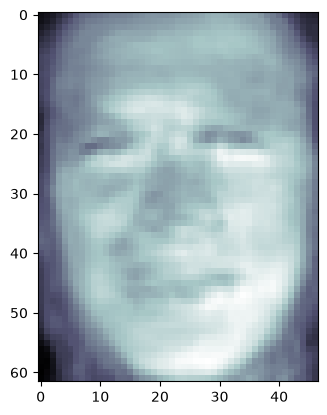

In [ ]:
# write your commented code here
assert pca.components_.shape == (150,2914)

# Extract the first Eigenvector from covariance matrix
first_principle = pca.components_[0]
assert first_principle.shape == (2914, )

# Reshape the Covariance Matrix
first_principle = first_principle.reshape(62, 47)

# Visualize grey scale Image
plt.imshow(first_principle, cmap='bone')

## 1d) [5 pts]


*   Explain your intuition about the visualized eigenvector as an image in 2-3 lines. What does it mean? What does it look like?

**Write your answer here:**



## 1e) [5 pts]
Use plt.subplots to visualize the first 50 eigenfaces. Visualize them in a 5 by 10 array of eigenfaces using subplots.

In [ ]:
# write your commented code here to Plot the first 50 eigenfaces


## 1f) [5 pts]
Repeat part 2b) but this time with 1348 components. Then
use plt.subplots to visualize the **last** 50 eigenfaces. Visualize them in a 5 by 10 array of eigenfaces.

In [ ]:
# write your code here to Plot the last 50 eigenfaces


## 1g) [5 marks]


*   Explain your intuition about the viuslized eigenfaces in 2-3 lines. what do they mean? what do they look like?

**Write your answer here:**



## Problem 2: Denoising using PCA [15 pts]

Run the following cell to load and visualize the faces again:

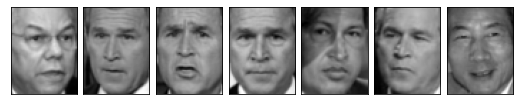

In [ ]:
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt

faces = fetch_lfw_people(min_faces_per_person=60)
# Plot the images
fig, ax = plt.subplots(1, 7, figsize=(9, 5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(7):
    ax[i].imshow(faces.images[i], cmap='binary_r')

Use reshape method to reshpe this data from (1348, 62, 47)
to (1348, 2914) such that X is the reshaped data:


In [ ]:
#write your code here to reshape the data
# Same code shared from the previous section
# Assert the Input Shape
assert faces.images.shape == (1348, 62, 47)

# Reshape into X
X = faces.images.reshape(1348, -1)

# Assert the X.shape
assert X.shape == (1348, 2914)

## 2a) [5 pts]
Generate a random matrix sampled from normal distribution with mean equal to 1 and standard deviation equal to 0.2 with the size of X. Name this matrix noise and add this to the X to get noisy_X. Then run the cell to visualize some of the noisy images.

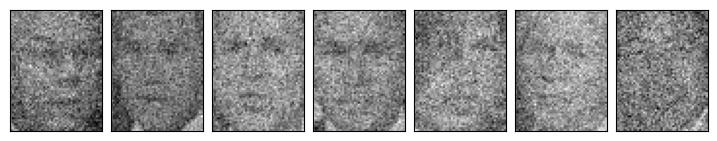

In [21]:
# write your code here
noise = np.random.normal(loc=1, scale=0.2, size=(1348, 2914))
noisy_X = X + noise
fig, ax = plt.subplots(1, 7, figsize=(9, 5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(7):
    ax[i].imshow(noisy_X[i].reshape(62, 47), cmap='binary_r')

##2b) [5 pts]
Denoise the images using PCA algorithm. Choose $k$ such that 80 % of variance in data is captured. name the denoised data "filtered".

In [22]:
# write the denoising code here name the denoised data "filtered"
variance_80 = PCA(0.8).fit(noisy_X)
components = pca.transform(noisy_X)
print(components.shape)
filtered = pca.inverse_transform(components)

(1348, 150)


Run the next cell to visualize it on the first 7 denoised images.

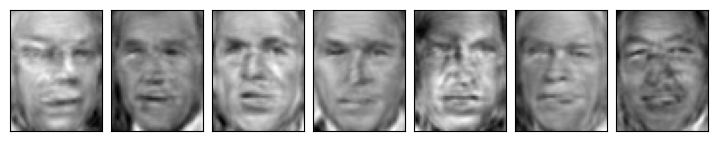

In [23]:
fig, ax = plt.subplots(1, 7, figsize=(9, 5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(7):
    ax[i].imshow(filtered[i].reshape(62, 47), cmap='binary_r')

##2c) [5 pts]
Repeat 3b with the  $k$ that it captures 40 % of variance in data and then visiualize the first 7 denoised images.

In [24]:
# write the denoising code here name the denoised data "filtered"
variance_80 = PCA(0.4).fit(noisy_X)
components = pca.transform(noisy_X)
print(components.shape)
filtered = pca.inverse_transform(components)

(1348, 150)


Run the next cell to visualize some of the denoised images.

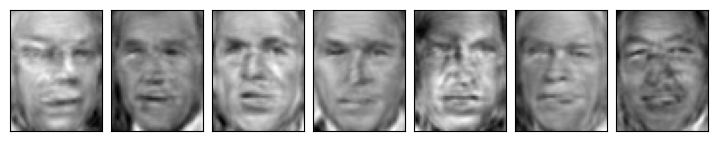

In [25]:
fig, ax = plt.subplots(1, 7, figsize=(9, 5),
                       subplot_kw={'xticks':[], 'yticks':[]},
                       gridspec_kw=dict(hspace=0.1, wspace=0.1))
for i in range(7):
    ax[i].imshow(filtered[i].reshape(62, 47), cmap='binary_r')



*    Compare the results of 3c with 3b and write your conclusion in 2-3 lines.

 **Write your conclusion here:**



